## **Cell 1: Imports and config**

In [1]:
import random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
assert (PROJECT_ROOT / "data").exists(), f"Wrong project root: {PROJECT_ROOT}. Start Jupyter from the project folder."
DATA_ROOT    = PROJECT_ROOT / "data" / "raw"
CATEGORY     = "metal_nut"
CAT_DIR      = DATA_ROOT / CATEGORY
REPORT_DIR   = PROJECT_ROOT / "reports" / "metrics"
FIG_DIR      = PROJECT_ROOT / "reports" / "figures"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---- Experiment settings (record these in your report) ----
IMAGE_SIZE   = 256     # resize 700x700 -> 256x256, no cropping
BATCH_SIZE   = 8
VAL_FRACTION = 0.10    # share of train/good held out for threshold selection
SEED         = 42
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| data exists:", CAT_DIR.exists())

Device: cuda | data exists: True


## **Cell 2: Dataset class**

In [2]:
class MVTecDataset(Dataset):
    """Returns image, mask, label, defect_type, path for one MVTec AD category."""

    def __init__(self, records, image_size=256):
        self.records = records.reset_index(drop=True)
        self.image_size = image_size
        self.img_tf = T.Compose([
            T.Resize((image_size, image_size), interpolation=T.InterpolationMode.BILINEAR),
            T.ToTensor(),
            T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ])

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        r = self.records.iloc[idx]
        image = self.img_tf(Image.open(r["path"]).convert("RGB"))

        mp = r["mask_path"]
        if isinstance(mp, str) and mp != "":
            m = Image.open(mp).convert("L")
            # NEAREST keeps the mask binary (no blurred in-between values)
            m = m.resize((self.image_size, self.image_size), Image.Resampling.NEAREST)
            mask = torch.from_numpy((np.array(m) > 0).astype(np.float32)).unsqueeze(0)
        else:
            mask = torch.zeros(1, self.image_size, self.image_size)

        return {
            "image": image,                      # (3, H, W), ImageNet-normalized
            "mask": mask,                        # (1, H, W), values 0 or 1
            "label": int(r["label"]),            # 0 = normal, 1 = anomalous
            "defect_type": r["defect_type"],
            "path": r["path"],
        }

## **Cell 3: Build the splits (fit / validation-normal / test)**

In [3]:
IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp"}

def list_images(folder):
    return sorted(p for p in folder.rglob("*") if p.suffix.lower() in IMG_EXT)

def build_records(cat_dir):
    rows = []
    for p in list_images(cat_dir / "train" / "good"):
        rows.append(dict(split="train", defect_type="good", path=str(p), mask_path=None, label=0))
    for d in sorted((cat_dir / "test").iterdir()):
        if not d.is_dir():
            continue
        for p in list_images(d):
            if d.name == "good":
                rows.append(dict(split="test", defect_type="good", path=str(p), mask_path=None, label=0))
            else:
                mp = cat_dir / "ground_truth" / d.name / f"{p.stem}_mask.png"
                rows.append(dict(split="test", defect_type=d.name, path=str(p), mask_path=str(mp), label=1))
    return pd.DataFrame(rows)

records   = build_records(CAT_DIR)
train_all = records[records.split == "train"]

# hold out some NORMAL training images for threshold selection later
val_normal = train_all.sample(frac=VAL_FRACTION, random_state=SEED)
train_fit  = train_all.drop(val_normal.index)
test_df    = records[records.split == "test"]

print("train_fit  (build memory bank):", len(train_fit))
print("val_normal (threshold later)  :", len(val_normal))
print("test       (final eval only)  :", len(test_df))

# save the split so every later notebook uses exactly the same images
splits = pd.concat([
    train_fit.assign(role="fit"),
    val_normal.assign(role="val_normal"),
    test_df.assign(role="test"),
])

splits_out = splits.copy()
splits_out["path"] = splits_out["path"].apply(lambda p: Path(p).relative_to(PROJECT_ROOT).as_posix())
splits_out["mask_path"] = splits_out["mask_path"].apply(
    lambda p: Path(p).relative_to(PROJECT_ROOT).as_posix() if isinstance(p, str) else "")
splits_out.to_csv(REPORT_DIR / f"{CATEGORY}_splits.csv", index=False)
print("Saved split file:", REPORT_DIR / f"{CATEGORY}_splits.csv")

train_fit  (build memory bank): 198
val_normal (threshold later)  : 22
test       (final eval only)  : 115
Saved split file: c:\Users\ASUS\Desktop\AI_Projects\Industrial-defect-detection\reports\metrics\metal_nut_splits.csv


## **Cell 4: DataLoaders**

In [4]:
train_ds = MVTecDataset(train_fit,  IMAGE_SIZE)
val_ds   = MVTecDataset(val_normal, IMAGE_SIZE)
test_ds  = MVTecDataset(test_df,    IMAGE_SIZE)

# num_workers=0 is the safest on Windows + Jupyter
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

batch = next(iter(train_loader))
print("image :", batch["image"].shape, batch["image"].dtype)
print("mask  :", batch["mask"].shape, batch["mask"].dtype)
print("labels:", batch["label"])
print("image value range:", float(batch["image"].min()), "to", float(batch["image"].max()))

image : torch.Size([8, 3, 256, 256]) torch.float32
mask  : torch.Size([8, 1, 256, 256]) torch.float32
labels: tensor([0, 0, 0, 0, 0, 0, 0, 0])
image value range: -1.8610327243804932 to 2.4482791423797607


## **Cell 5: Sanity checks on every sample**

In [5]:
problems = []
vanished = []

for i in range(len(test_ds)):
    s = test_ds[i]
    vals = set(torch.unique(s["mask"]).tolist())
    if not vals <= {0.0, 1.0}:
        problems.append((s["path"], "mask not binary"))
    if s["image"].shape[-2:] != s["mask"].shape[-2:]:
        problems.append((s["path"], "image/mask size mismatch"))
    if s["label"] == 0 and s["mask"].sum() != 0:
        problems.append((s["path"], "normal image has non-empty mask"))
    if s["label"] == 1 and s["mask"].sum() == 0:
        vanished.append(s["path"])

print("Problems found           :", len(problems))
print("Defect masks that vanished after resize:", len(vanished))
for p in problems[:5]:
    print(p)

Problems found           : 0
Defect masks that vanished after resize: 0


## **Cell 6: Visualize processed samples**

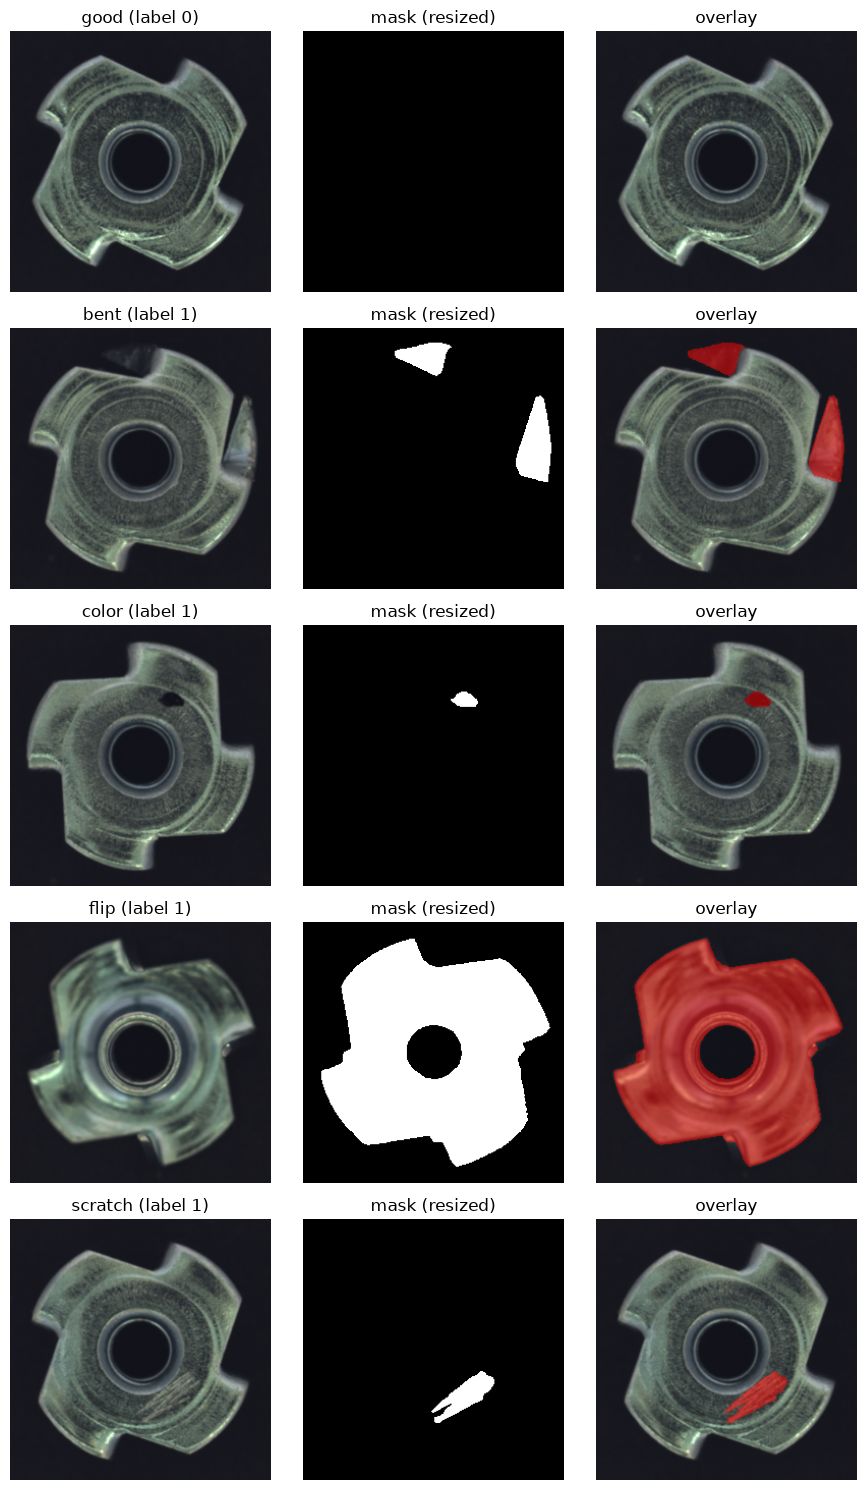

In [6]:
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std  = torch.tensor(IMAGENET_STD).view(3, 1, 1)

def denorm(t):
    return (t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

test_reset = test_df.reset_index(drop=True)
idx = [int(test_reset.index[test_reset.defect_type == t][0]) for t in ["good", "bent", "color", "flip", "scratch"]]

fig, axes = plt.subplots(len(idx), 3, figsize=(9, 3 * len(idx)))
for row, i in zip(axes, idx):
    s = test_ds[i]
    img, m = denorm(s["image"]), s["mask"][0].numpy()
    overlay = img.copy()
    overlay[m > 0] = 0.5 * overlay[m > 0] + 0.5 * np.array([1, 0, 0])
    row[0].imshow(img);     row[0].set_title(f"{s['defect_type']} (label {s['label']})")
    row[1].imshow(m, cmap="gray"); row[1].set_title("mask (resized)")
    row[2].imshow(overlay); row[2].set_title("overlay")
    for a in row:
        a.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / f"{CATEGORY}_processed_samples.png", dpi=150)
plt.show()

## **Cell 7: Why masks must use nearest-neighbor resizing**

In [7]:
r = test_df[test_df.defect_type == "color"].iloc[0]
m = Image.open(r["mask_path"]).convert("L")

m_near = np.array(m.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.NEAREST))
m_bil  = np.array(m.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR))

print("NEAREST  unique values:", np.unique(m_near))
print("BILINEAR unique values:", len(np.unique(m_bil)), "different values ->", np.unique(m_bil)[:8], "...")

NEAREST  unique values: [  0 255]
BILINEAR unique values: 81 different values -> [0 1 2 3 4 5 7 8] ...


## **Cell 8: How small do defects become after resizing?**

In [8]:
from scipy import ndimage

rows = []
for _, r in test_df[test_df.defect_type != "good"].iterrows():
    m_full  = np.array(Image.open(r["mask_path"]).convert("L")) > 0
    m_small = np.array(Image.open(r["mask_path"]).convert("L")
                       .resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.NEAREST)) > 0
    _, n_regions = ndimage.label(m_small)
    rows.append(dict(defect_type=r["defect_type"],
                     area_700_px=int(m_full.sum()),
                     area_256_px=int(m_small.sum()),
                     area_percent=round(100 * m_full.mean(), 3),
                     n_regions=n_regions))

size_df = pd.DataFrame(rows)
print(size_df.groupby("defect_type")[["area_700_px", "area_256_px", "area_percent"]]
      .agg(["min", "median", "max"]).round(2).to_string())
print("\nSmallest defect after resize (pixels):", size_df.area_256_px.min())
size_df.to_csv(REPORT_DIR / f"{CATEGORY}_defect_sizes.csv", index=False)

            area_700_px                   area_256_px                 area_percent              
                    min    median     max         min   median    max          min median    max
defect_type                                                                                     
bent               3458    9177.0   23025         455   1227.0   3075         0.71   1.87   4.70
color              2135   10242.0   32188         284   1368.5   4298         0.44   2.09   6.57
flip             234449  236046.0  238751       31348  31580.0  31915        47.85  48.17  48.72
scratch            9302   27129.0   60275        1249   3643.0   8070         1.90   5.54  12.30

Smallest defect after resize (pixels): 284
